In [1]:
import os, sys
%pylab inline
plt.style.use('default')
import pandas as pd
from importlib import reload
spines_off = lambda ax: [ax.spines[side].set_visible(False) for side in ['top', 'right']]

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [2]:
import dnos
import dnos.src.paths as paths

In [3]:
import dnos.src.data as dnos_data
reload(dnos_data)  
df, odour_cols = dnos_data.tidy_pandan(do_zscore=True)

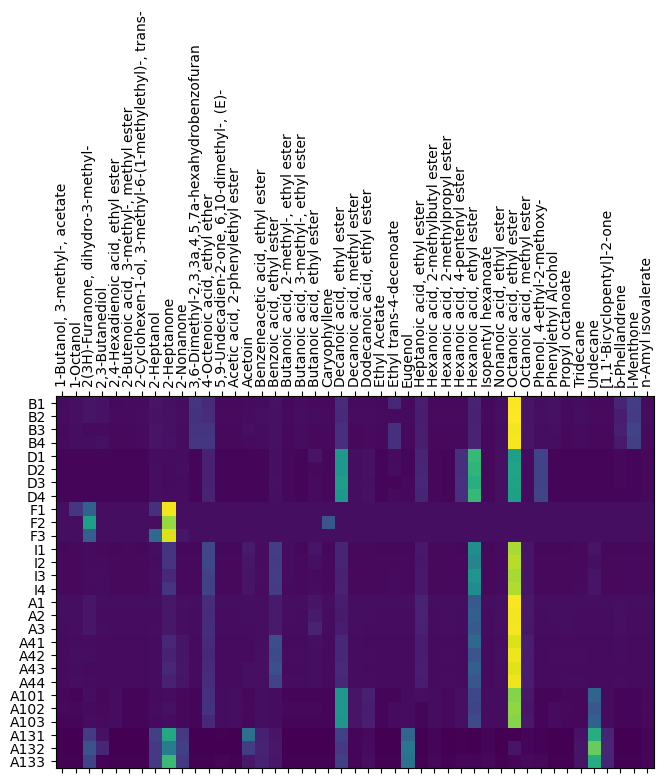

In [4]:
matshow(df[odour_cols].values)
gca().set_xticks(range(len(odour_cols)))
gca().set_xticklabels(odour_cols, rotation=90)
gca().set_yticks(range(len(df)))
gca().set_yticklabels([f"{row['Sample']}{row['Replicate']}" for _, row in df.iterrows()]);

In [5]:
import dnos.src.erecta as erecta
import dnos.src.common as common
reload(common)
reload(erecta);

In [6]:
reload(dnos_data); 
reload(common)
reload(erecta)
A = erecta.Analysis(k=7)
results = A.fit_models()#results=results)

In [7]:
A.compute_sparsity()
A.compute_pc_var_overlap()
A.compute_confusion_matrices()
A.compute_p_values(n_rand=1000)

100%|██████████| 1000/1000 [00:14<00:00, 69.30it/s]


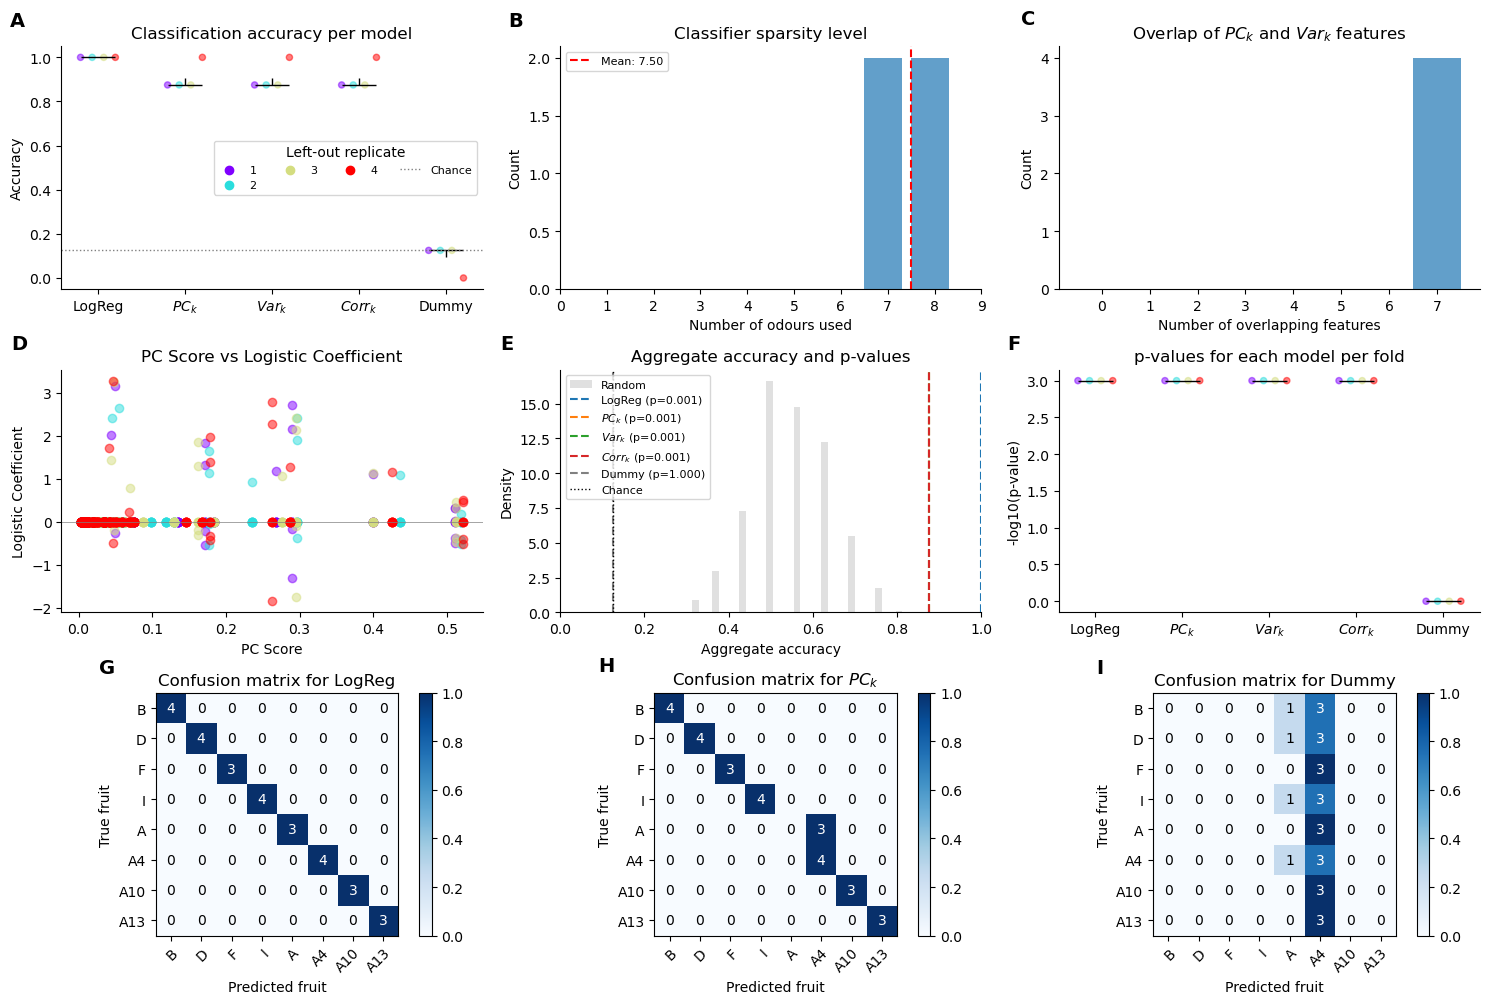

In [8]:
reload(erecta)
pr = erecta.PlotResults(A)
pr.plot_figure()
savefig(os.path.join(paths.figs_path, "erecta_all.pdf"), bbox_inches=None)

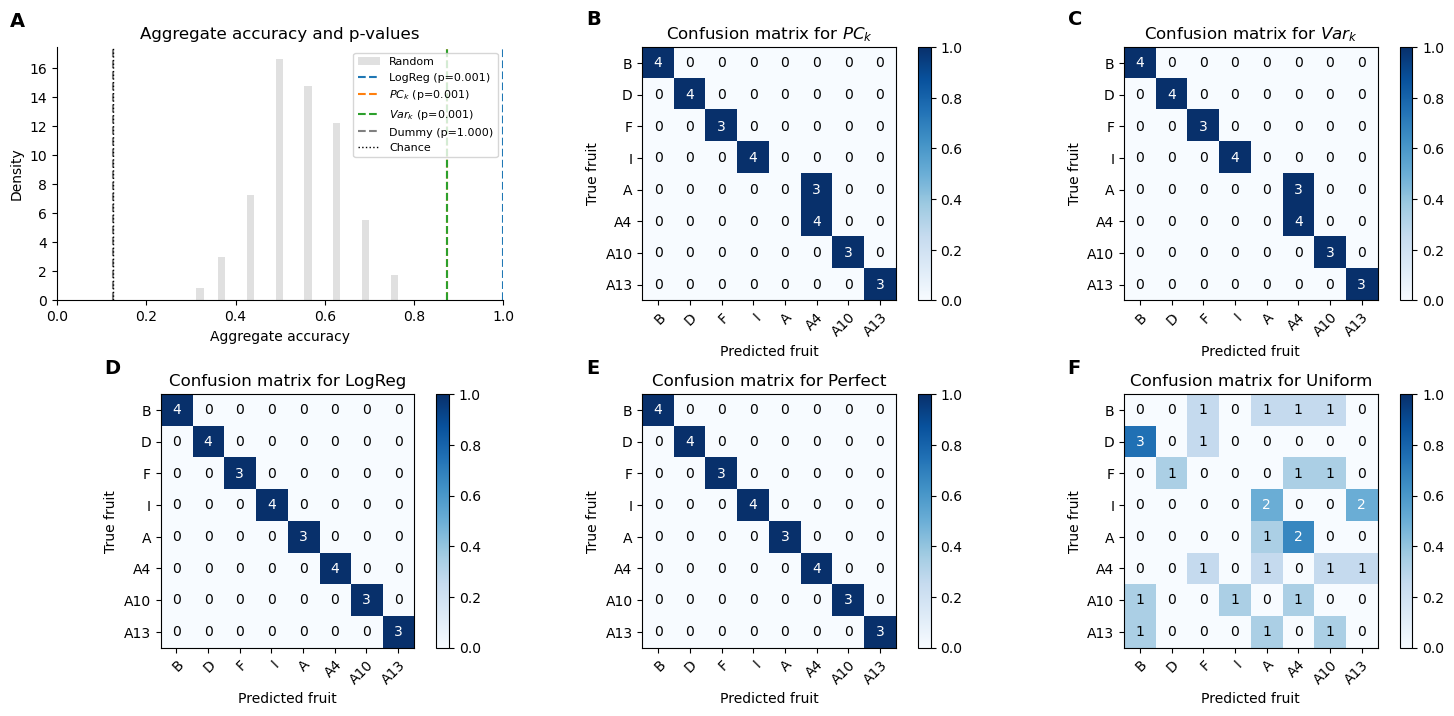

In [9]:
reload(common)
reload(erecta)
pr = erecta.PlotResults(A)
pr.plot_figure(panels=[
    (0, 0, "A", pr.plot_aggregate_p_values, ["logreg", "pc_k", "var_k", "dummy"]),
    (0, 1, "B", pr.plot_confusion_matrix, "pc_k"),
    (0, 2, "C", pr.plot_confusion_matrix, "var_k"),
    (1, 0, "D", pr.plot_confusion_matrix, "logreg"), 
    (1, 1, "E", pr.plot_confusion_matrix, "perfect"),
    (1, 2, "F", pr.plot_confusion_matrix, "uniform")
])
plt.savefig(os.path.join(paths.figs_path, "erecta.pdf"), bbox_inches=None)